DX703 Final Project Milestone: Data Exploration and Baseline Modeling
======================

## Due Date: Sunday, November 15th at 11:59pm (with 2 hour plus 1 minute grace period)

**No late submissions!**


### Purpose and scope

This is the **first of two project submissions**. Choose **one** classification dataset—**Food-101** (images) or **HuffPost News Category** (text)—and carry it from initial exploration through a reproducible **baseline model**.

In this milestone you will:

1. Explore both datasets briefly; select and investigate one (**10 pts**).
2. Frame its classification problem, challenges, and evaluation strategy (**15 pts**).
3. Clean and preprocess your data and create reproducible train/validation/test splits (**30 pts**).
4. Train and evaluate a simple baseline using **training and validation data only** (**30 pts**).

**The later final submission** will cover a more capable custom model, a pretrained/transfer-learning model, comparison and selection, a refined final model, and the final technical report. Details of that submission will be posted separately.

**Important conventions**

- Retain your chosen dataset for the entire project. Remove the unused dataset's starter cells **after** exploring both.
- Use a fixed random seed, state all data-selection choices and important hyperparameters, and keep the notebook runnable from top to bottom.
- You may use a documented, reproducible subset for experiments if computing resources are limited; explain its size and selection process. Do not represent subset performance as full-dataset performance.
- **Keep the test set untouched in this milestone.** Select models and discuss baseline performance using *validation* results. Save test-set evaluation for the final submission.
- Write each graded explanation in its designated Python string answer variable (`a1a`, `a1b`, etc.). Do not modify the following **Graded Answer** print cells. You may add code cells, plots, or comments as necessary. Follow the approximate word-count guidelines in each problem (100–150 words for Problems 1, 3, and 4; 75–125 words for Problem 2).
- Include an AI-use disclosure at the end in accordance with CDS policy.

**Grading — 85 points total**

| Problem | Grading basis | Points |
|---|---|---:|
| 1. Choose the Dataset | 5 questions × 2 pts, including supporting code, tables, and plots | **10** |
| 2. Frame the Problem | 5 questions × 3 pts, including supporting evidence | **15** |
| 3. Data Preparation and Splits | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| 4. Baseline Model | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| **Total** | | **85** |

**How your work will be assessed:** For Problems 1–2, each question will be assessed as a whole, including your written response and the supporting code, tables, or plots. For Problems 3–4, programming and written answers receive separate point allocations.

Programming will be assessed primarily for **correctness and completeness**, with attention to reproducibility, organization, and clarity. Written answers should accurately explain *your own implementation and results*, referring to specific evidence from the notebook. Code may be reviewed and tested, so explanations alone do not earn programming credit. Your submitted notebook must run from beginning to end without errors.

**Use of AI in grading:** We will use AI tools to assist with reviewing code, evaluating written responses, and identifying possible errors or omissions. However, **AI will not make final grading decisions. Every proposed point deduction will be reviewed by a human grader before it is applied.** Human graders retain responsibility for determining and assigning final scores.

In [1]:
# # --- Hugging Face Datasets
# from datasets import load_dataset, DatasetDict
# from datasets.features import ClassLabel

---

### Dataset Two (Text): HuffPost Dataset

**Load HuffPost (headline + summary + category)**

**Note:** This loads a **Hugging Face `Dataset`**, not a NumPy array or Pandas DataFrame.
- Each record is a **dictionary** with fields such as `"headline"`, `"short_description"`, and `"category"`.
- You can access columns by name (e.g., `huff["headline"]`) and check dataset size with `len(huff)`.
- Treat it as a table of text fields — you’ll handle tokenization and vectorization later during preprocessing.
- The typical BERT-compatible separator is used to construct the sample texts

        `headline [SEP] short-description`



---

# **Problem 1 — Choose the Dataset (10 pts)**

Objective

In this problem, you will explore the two provided datasets and select one to use for your final project.  
Your goal is to understand the structure, content, and challenges of the dataset through basic exploratory data analysis (EDA).  
By the end of this milestone notebook, you should be able to explain what makes the dataset interesting, identify potential modeling challenges (e.g., imbalance, ambiguity, quality issues), and justify why it is a good choice for your classification project.


What to Do

1. **Load both datasets** and examine the outputs of the template code provided.  
   After this brief inspection, **choose one dataset for your project** and **delete the template code for the other.**  For your chosen dataset, continue with the remaining steps.

2. **Inspect** the dataset's basic properties:  
   - **Number of samples and classes:**  
     Determine how many total examples and distinct categories are present. Verify that the counts match expectations (e.g., 101 food classes or 41 news topics).  
   - **Example records or images:**  
     View several samples to understand the input format, diversity, and potential quality issues.  
     For images, note lighting or composition differences; for text, read a few headlines and summaries to see how expressive they are (done for you in template code). 
   - **Distribution of labels (check for imbalance):**  
     Plot or tabulate label frequencies to see whether some classes dominate. Imbalanced datasets can bias model training and may require special handling.  
   - **Missing or inconsistent data:**  
     Look for empty fields, unreadable images, duplicate entries, or mislabeled samples. Handle or document any issues you find.  
   - **Overlapping or ambiguous class labels:**  
     Identify categories that may not be clearly distinct—e.g., “apple pie” vs. “cheesecake,” or “POLITICS” vs. “WORLD NEWS.”  
     Ambiguity in labels can increase confusion between classes and reduce model accuracy.

3. **Visualize key aspects:**  
   Extend the template code to complete the EDA for your chosen dataset:  
   - **Images:**  
     Create visual summaries to better understand the data (some are implemented in the template code).  
     - Verify that the dataset is balanced across classes.  
     - Display a small grid of random images to check variation in appearance, composition, and background (done in template code).  
     - Compare image sizes to determine whether resizing or normalization will be needed.  
     - Examine lighting and color balance—many web-scraped photos vary widely in brightness, saturation, and white balance.  
   - **Text:**  
     Visualize class balance and linguistic properties (some implemented in the template code).  
     - Plot the number of samples per label to confirm class balance or imbalance.  
     - Compute basic text statistics such as average word count or vocabulary size.  
     - Examine examples for duplicates, near-duplicates, or entries that might fit multiple categories.  
     - *(Optional)* Generate a word-frequency plot or word cloud to highlight distinctive terms for a few classes.

4. **Answer the graded questions below.**


In [2]:
# Your code here, add as many cells as you like. Provide organization and structure by appropriate comments, labels, and variable names. Explain what
# you are doing in case you come back to this in a year. 


#### ----------------------------------------------------- ####

                
#      packages       
# ======================================
# 

import os
os.environ["KERAS_BACKEND"] = "tensorflow"


import numpy                    as np
import pandas                   as pd
import matplotlib.pyplot        as plt
import seaborn                  as sns

from matplotlib.ticker          import StrMethodFormatter

import re
import time

from IPython.display            import display, HTML, Markdown


from sklearn.model_selection    import train_test_split
from sklearn.preprocessing      import LabelEncoder
from sklearn.metrics            import classification_report, confusion_matrix, f1_score

import keras
import keras_hub                
import tensorflow               as tf

from keras                      import mixed_precision                   
# mixed_precision.set_global_policy("mixed_float16")
mixed_precision.set_global_policy("float32")



# --- Hugging Face Datasets
from datasets import load_dataset, DatasetDict
from datasets.features import ClassLabel


##_____ just some helper _____ ##: 

def view_content(df):
    if isinstance(df, pd.Series):
        df = df.to_frame()

    with pd.option_context("display.max_colwidth", None):
        html = df.to_html(
            max_rows=None,
            max_cols=None,
            escape=True,
        )

    display(HTML(
        '<div style="width:100%; overflow-x:auto;">'
        '<style>'
        '.full-text-table td, .full-text-table th {'
        '    white-space:pre-wrap;'
        '    overflow-wrap:anywhere;'
        '    min-width:100px;'
        '    max-width:500px;'
        '    text-align:left;'
        '    vertical-align:top;'
        '}'
        '</style>'
        + html.replace('class="dataframe"', 'class="dataframe full-text-table"')
        + '</div>'
    ))

def format_hms(seconds):
    """Format elapsed seconds as H:MM:SS."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

                
#      dataset       
# ======================================
# 

URL = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff_all = load_dataset("json", data_files=URL, split="train")

df = huff_all.to_pandas()





I0000 00:00:1794688572.065912   29964 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
                
#      review missingness       
# ======================================
# 
df = (
    df
    .replace(r"^\s*$", pd.NA, regex=True)
    .assign(date=lambda x: pd.to_datetime(x["date"], errors="coerce"))
)

quality = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean().mul(100).round(4),
        "unique_values": df.nunique()
    })
    .sort_values("missing_pct", ascending=False)
)



display(HTML("<h2>Missing summary table:"), quality)


##### •••••• ####
headline_less = len(df.query("headline.notna() and short_description.isna()"))

print(f""" total headline-less news: {headline_less}""")

print(f" % = {headline_less / len(df) * 100:.4f}%")

,dtype,missing,missing_pct,unique_values
authors,str,36620,18.2322,27992
short_description,str,19712,9.8141,178352
headline,str,6,0.0030,199343
category,str,0,0.0000,41
link,str,0,0.0000,200812
date,datetime64[s],0,0.0000,2309


 total headline-less news: 19707
 % = 9.8117%


In [4]:
                
#      check duplicates       
# ======================================
# 

duplicate_summary = pd.Series({
    "exact_duplicate_rows": df.duplicated().sum(),
    "repeated_nonmissing_links": df["link"].dropna().duplicated().sum(),
    "repeated_nonmissing_headlines": df["headline"].dropna().duplicated().sum()
})

display(HTML("<h2>duplicate_summary"), duplicate_summary)

exact_duplicate_rows               13
repeated_nonmissing_links          41
repeated_nonmissing_headlines    1504
dtype: int64

In [5]:
                
#      check headlines repetitions       
# ======================================
# 
df_duplicate_dates = (
    df
    .assign(date=lambda x: pd.to_datetime(x["date"], errors="coerce").dt.normalize())
    .dropna(subset=["headline", "date"])
    .assign(
        distinct_dates=lambda x: (
            x.groupby("headline")["date"].transform("nunique")
        )
    )
    .query("distinct_dates > 1")
    .sort_values(["headline", "date"])
)
headline_summary = (
    df_duplicate_dates
    .groupby("headline", as_index=False)
    .agg(
        rows=("date", "size"),
        distinct_dates=("date", "nunique"),
        earliest_date=("date", "min"),
        latest_date=("date", "max")
    )
    .sort_values(["distinct_dates", "rows"], ascending=False)
)

display(HTML("<h2>summary checking headline"),headline_summary.head(10))

,headline,rows,distinct_dates,earliest_date,latest_date
209,Sunday Roundup,90,89,2014-04-20,2016-07-24
214,The 20 Funniest Tweets From Women This Week,80,80,2015-04-25,2018-05-25
282,Weekly Roundup of eBay Vintage Clothing Finds ...,59,58,2012-02-03,2013-08-20
284,Weekly Roundup of eBay Vintage Home Finds (PHO...,54,54,2012-02-07,2013-08-26
270,Watch The Top 9 YouTube Videos Of The Week,46,46,2012-01-28,2013-02-02
227,The Funniest Tweets From Parents This Week,41,41,2014-04-20,2018-01-19
38,Animal Photos Of The Week,36,36,2012-01-29,2014-04-06
49,Best Parenting Tweets: What Moms And Dads Said...,33,33,2012-07-09,2014-04-13
228,The Funniest Tweets From Women This Week,33,33,2014-04-26,2015-03-21
78,Extreme Weather Photos Of The Week,29,29,2013-03-24,2014-02-09


In [6]:
                
#      inspect target (col category)       
# ======================================
# 
target = "category"
df_eda = (
    df
    .assign(**{
        target: lambda x: x[target].replace(r"^\s*$", pd.NA, regex=True)
    })
)

category_summary = (
    df_eda[target]
    .value_counts()
    .loc[lambda x: x > 0]
    .rename_axis(target)
    .reset_index(name="articles")
    .assign(
        pct=lambda x: x["articles"].div(x["articles"].sum()).mul(100),
        cumulative_pct=lambda x: x["pct"].cumsum(),
        fewer_than_10=lambda x: x["articles"] < 10
    )
)

display(HTML("<h2>Target(category) summary"),category_summary.round(2))

,category,articles,pct,cumulative_pct,fewer_than_10
0,POLITICS,32739,16.30,16.30,False
1,WELLNESS,17827,8.88,25.18,False
2,ENTERTAINMENT,16058,7.99,33.17,False
3,TRAVEL,9887,4.92,38.09,False
4,STYLE & BEAUTY,9649,4.80,42.90,False
5,PARENTING,8677,4.32,47.22,False
6,HEALTHY LIVING,6694,3.33,50.55,False
7,QUEER VOICES,6314,3.14,53.69,False
8,FOOD & DRINK,6226,3.10,56.79,False
9,BUSINESS,5937,2.96,59.75,False


## Graded Questions (2 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

#### ✅ A. **Dataset Summary:**
   Describe your chosen dataset  (as if explaining to your *clueless boss* what you are working on).
   - State which dataset you are going to use.   
   - What kind of data does it contain (images or text)?  
   - How many samples and classes are there?  
   - What is the task you’ll perform (classification into what categories)?
   - What is the potential business use for this dataset?

In [7]:
# Your answer here, NOT in the next cell  

a1a = """
For this milestone, I am using the text data about Huffpost news articles. 
The data from Huggingface is transformed into Pandas dataframe for easier workflow. 

The data contains 200,853 rows with 41 news categories. 
The task for this data is to have a model that can classify a news article with the appropriate news category.

Some usefulness of performing or creating this model is to automatically assigned a writing or article into appropriate news category, 
or to organize an article for better viewership. 

"""

In [8]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a}")

a1a = 
For this milestone, I am using the text data about Huffpost news articles. 
The data from Huggingface is transformed into Pandas dataframe for easier workflow. 

The data contains 200,853 rows with 41 news categories. 
The task for this data is to have a model that can classify a news article with the appropriate news category.

Some usefulness of performing or creating this model is to automatically assigned a writing or article into appropriate news category, 
or to organize an article for better viewership. 




#### ✅ B. **Initial Observations:**  
   What stood out to you from your EDA?  
   - Did you notice any imbalanced or ambiguous classes?  
   - Any patterns, anomalies, or potential sources of bias?  
   - For images: note any variation in lighting, composition, or color.  
   - For text: mention redundancy, topic overlap, or very short examples.

In [9]:
# Your answer here, NOT in the next cell

a1b = """
From reviewing the features, there are many articles with missing authors (>36,000; 18.2%). 
Most of the time, authors may not be necessary to be included into the tokens, 
so this issue may not be detrimental.

There are only 6 articles without headlines/title (0.003%). This is pretty minimal. 

There are 19,712 (9.81%) missing the description or the content. 
This is quite important as the article content should be where most of the features are derived from.


From reviewing the target or the news category, there are some questionable duplicates. 
For example:

**repetitive** 
- `arts`, `arts & cultures`, `cultures & arts`
- `Worldpost`, `THE worldpost`, `world news` 
- `parents`, `parenting`
-  `style`, `style & beauty`

**prob could be repetitive**
- `green` & `environment`
- `divorce` & `wedding`
- `taste` & `food & drink`

**maybe overlap?**
- `money` vs `business`
- `healthy living` vs `wellness`
- `science` vs `tech`
- `college` vs `education`



*other issue*

- when combining the headline & content, I found that 
some articles have exact H&C, even same date...,
but different category label!.
    - There are some that have different dates;
    this makes me think that the editor adjusted the category 
    after the publication, to a more fitting category. 
    So I am thinking that for duplicates, I should use the last date.
"""

In [10]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b}")

a1b = 
From reviewing the features, there are many articles with missing authors (>36,000; 18.2%). 
Most of the time, authors may not be necessary to be included into the tokens, 
so this issue may not be detrimental.

There are only 6 articles without headlines/title (0.003%). This is pretty minimal. 

There are 19,712 (9.81%) missing the description or the content. 
This is quite important as the article content should be where most of the features are derived from.


From reviewing the target or the news category, there are some questionable duplicates. 
For example:

**repetitive** 
- `arts`, `arts & cultures`, `cultures & arts`
- `Worldpost`, `THE worldpost`, `world news` 
- `parents`, `parenting`
-  `style`, `style & beauty`

**prob could be repetitive**
- `green` & `environment`
- `divorce` & `wedding`
- `taste` & `food & drink`

**maybe overlap?**
- `money` vs `business`
- `healthy living` vs `wellness`
- `science` vs `tech`
- `college` vs `education`



*other issue*

- when c

#### ✅ C. **Challenges & Implications:**   
   Based on your inspection, what challenges might affect model performance or training (e.g., imbalance, ambiguous labels, variable quality)?  

In [11]:
# Your answer here, NOT in the next cell

a1c = """
As there are some categories with low count, the model may have difficult time to categorize the news for these low count labels.
For example, the lowest count is for Education with only 1004 (0.50%). 
The category with most articles is Politics with 16.30%, almost double the 2nd most with only 8.88%. 

In some of the categories, their labels could be merged due to possibility of 
that these labels are just a renamed version from Huffpost changing the label.


There are also repetitive news such as weekly updates, or weekly roundup, or weekly deals. 
These articles need some attentions or works so that they do not put too much weight in the model. 

"""

In [12]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1c = {a1c}")

a1c = 
As there are some categories with low count, the model may have difficult time to categorize the news for these low count labels.
For example, the lowest count is for Education with only 1004 (0.50%). 
The category with most articles is Politics with 16.30%, almost double the 2nd most with only 8.88%. 

In some of the categories, their labels could be merged due to possibility of 
that these labels are just a renamed version from Huffpost changing the label.


There are also repetitive news such as weekly updates, or weekly roundup, or weekly deals. 
These articles need some attentions or works so that they do not put too much weight in the model. 




#### ✅ D. **Preparation Ideas:**  
   What data-cleaning or preprocessing steps might help address these issues?  
   (You will not implement these yet—just describe what you might do later.)

In [13]:
# Your answer here, NOT in the next cell

a1d = """
Several ideas I plan to do to clean the dataset before building a model:
- remove those that are clearly duplicates (same content, same date, same headline).
- remove those with both no headlines and no contents, which is about 5 samples only.
- deal with weekly repetitive news such as weekly funny tweets, weekly ebay finds.
- deal with duplicated articles but assigned for different labels.
- merge some of the categories that are clearly repetitive or the same, while
 try to merge low count categories but quite similar (e.g., college vs education). 


"""

In [14]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1d = {a1d}")

a1d = 
Several ideas I plan to do to clean the dataset before building a model:
- remove those that are clearly duplicates (same content, same date, same headline).
- remove those with both no headlines and no contents, which is about 5 samples only.
- deal with weekly repetitive news such as weekly funny tweets, weekly ebay finds.
- deal with duplicated articles but assigned for different labels.
- merge some of the categories that are clearly repetitive or the same, while
 try to merge low count categories but quite similar (e.g., college vs education). 





#### ✅ E. **Reflection:**  
   Why did you choose this dataset over the other one?  
   - What makes it more interesting, realistic, or relevant for you?  
   - What do you expect to learn from working with it?

In [15]:
# Your answer here, NOT in the next cell

a1e = """
Processing text data is getting more attention recently due to the development of LLM.
While LLM seems to be used by many people, understanding the basics of text processing is still necessary.
In some example projects, processing texts for limited topics may not need LLM but just a simple NLP.
Thus, I want to deepen my skill in the NLP analyses. 

From this milestone project, I hope I could build some example works on text data or NLP.
Or, so that I could create my own portfolio project that is similar as this. 
"""

In [16]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1e = {a1e}")

a1e = 
Processing text data is getting more attention recently due to the development of LLM.
While LLM seems to be used by many people, understanding the basics of text processing is still necessary.
In some example projects, processing texts for limited topics may not need LLM but just a simple NLP.
Thus, I want to deepen my skill in the NLP analyses. 

From this milestone project, I hope I could build some example works on text data or NLP.
Or, so that I could create my own portfolio project that is similar as this. 



# Problem 2 — Frame the Problem (15 pts)

#### Objective

Identify the **key challenges** in your chosen dataset and outline **practical solutions** you would try, plus how you’ll **evaluate** them later.

#### Steps to follow

1. **Diagnose likely challenges (from your EDA):**

   Examples:
   * **Class imbalance:**
     Report label counts and an imbalance ratio (max / median). List any minority classes.
   * **Length/size variance:**
     For text, show length percentiles (50/75/90/95) and estimate truncation rate at candidate `max_text_length`s (e.g., 256/300/512). For images, summarize native resolutions.
   * **Noise/duplicates/leakage:**
     Note empty or malformed items, near-duplicates, and how you would prevent cross-split leakage.
   * **Ambiguous/overlapping labels:**
     Give 2–3 example pairs you expect to be confusable and why.
   * **Compute constraints:**
     Briefly state limits (RAM/GPU/CPU) that might affect batch size, sequence length, or image size.

2. **Map each challenge to a concrete solution plan:**

   Examples:
   * **Imbalance →** `class_weight` or oversampling; report which one you’d try first and why.
   * **Length/size →** pick a target `max_text_length` (e.g., 95th percentile) with masking; for images, standardize resize/crop and basic augmentation.
   * **Noise/duplicates →** dedupe (hash/near-dup), drop empty/very short items, document any relabeling.
   * **Ambiguity →** consider merging labels (if justified), or add features (bigrams/char-ngrams; simple image augmentations).
   * **Overfitting risk →** early stopping on your primary metric, dropout/weight decay, freeze-then-finetune plan (for pretrained features).

3. **Explore appropriate evaluation metrics:**

   Examples:
   * **Primary metric:** pick one aligned to your data (e.g., **macro-F1** if imbalanced; accuracy if balanced).
   * **Secondary metric(s):** per-class precision/recall, confusion matrix.
   * **Protocol:** stratified Train/Val/Test (e.g., 70/15/15), fixed seed, leakage checks.

4. **Answer the graded questions below.**



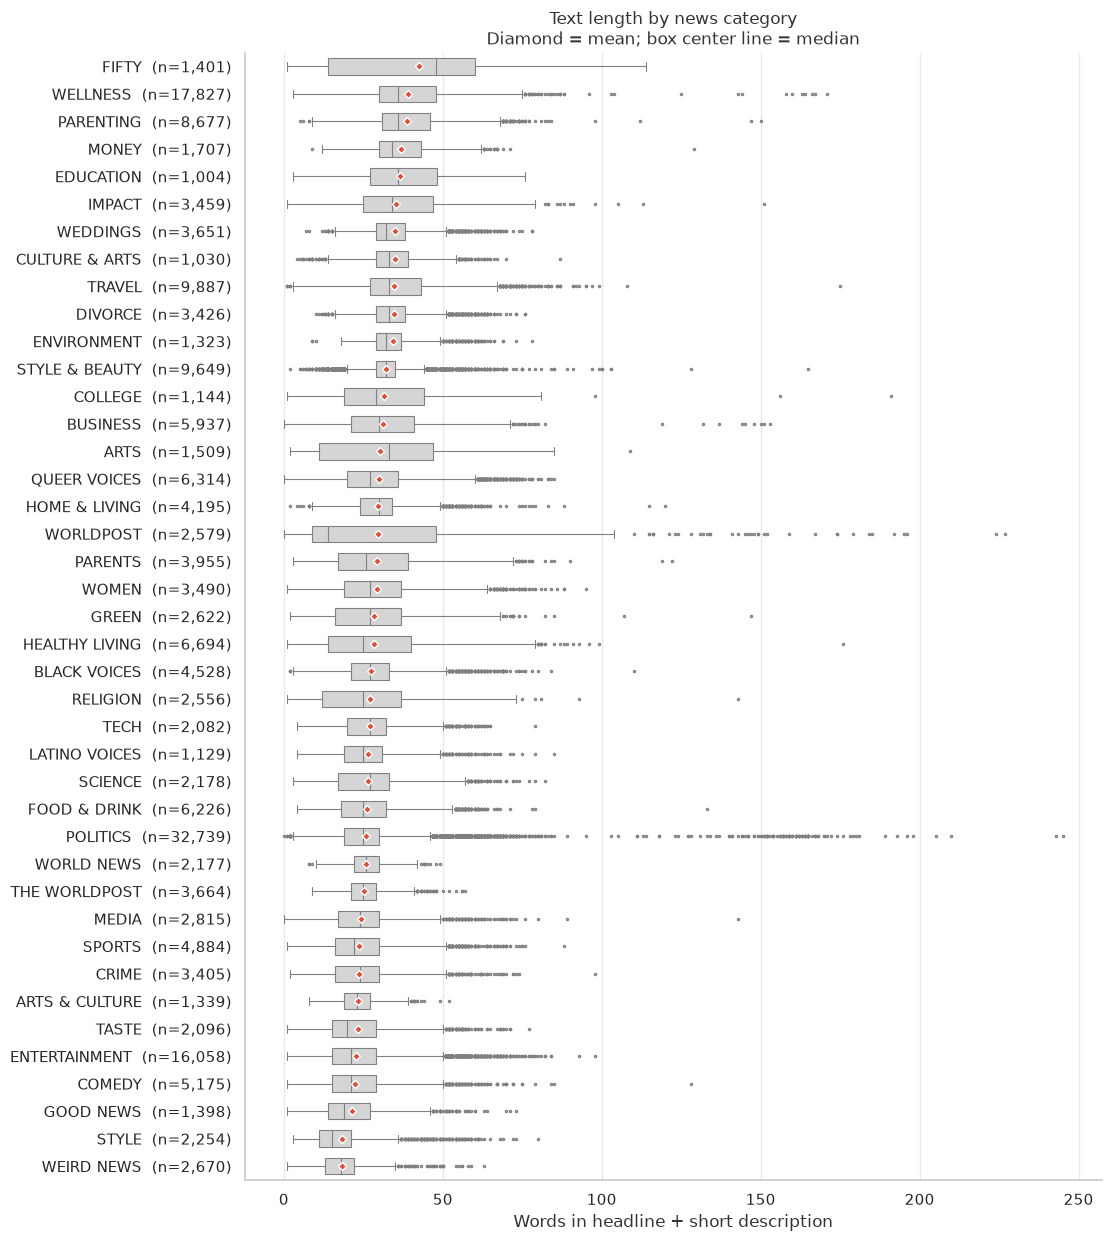

In [17]:
# Your code here, add as many cells as you like. Provide organization and structure by appropriate comments, labels, and variable names. Explain what
# you are doing in case you come back to this in a year. 

#### ----------------------------------------------------- ####

## _Reusable visual style
sns.set_theme(
    style="whitegrid",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": "#E8E8E8",
        "text.color": "#333333",
        "axes.labelcolor": "#333333"
    }
)

## _Missing or blank text contributes zero words
df_plot = (
    df
    .assign(
        date=lambda x: pd.to_datetime(x["date"], errors="coerce"),
        category=lambda x: x["category"].replace(r"^\s*$", pd.NA, regex=True),
        headline_words=lambda x: (
            x["headline"].fillna("").str.split().str.len()
        ),
        description_words=lambda x: (
            x["short_description"].fillna("").str.split().str.len()
        )
    )
    .assign(
        year=lambda x: x["date"].dt.year.astype("Int64"),
        text_words=lambda x: x["headline_words"] + x["description_words"]
    )
)

## _Change this to headline_words or description_words if preferred
word_col = "text_words"
word_label = "Words in headline + short description"

word_summary = (
    df_plot
    .dropna(subset=["category"])
    .groupby("category", observed=True)
    .agg(
        articles=(word_col, "size"),
        mean_words=(word_col, "mean"),
        median_words=(word_col, "median")
    )
    .sort_values("mean_words", ascending=False)
)

category_order = word_summary.index.tolist()

fig, ax = plt.subplots(
    figsize=(11, max(6, len(category_order) * 0.30)),
    layout="constrained"
)

sns.boxplot(
    data=df_plot,
    x=word_col,
    y="category",
    order=category_order,
    color="#D5D5D5",
    width=0.6,
    linewidth=0.8,
    fliersize=1.5,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#DD513A",
        "markeredgecolor": "white",
        "markersize": 4
    },
    ax=ax
)

ax.set_yticks(
    range(len(category_order)),
    labels=[
        f"{category}  (n={word_summary.loc[category, 'articles']:,})"
        for category in category_order
    ]
)

ax.set(
    title="Text length by news category\nDiamond = mean; box center line = median",
    xlabel=word_label,
    ylabel=""
)
ax.grid(axis="y", visible=False)

plt.show()

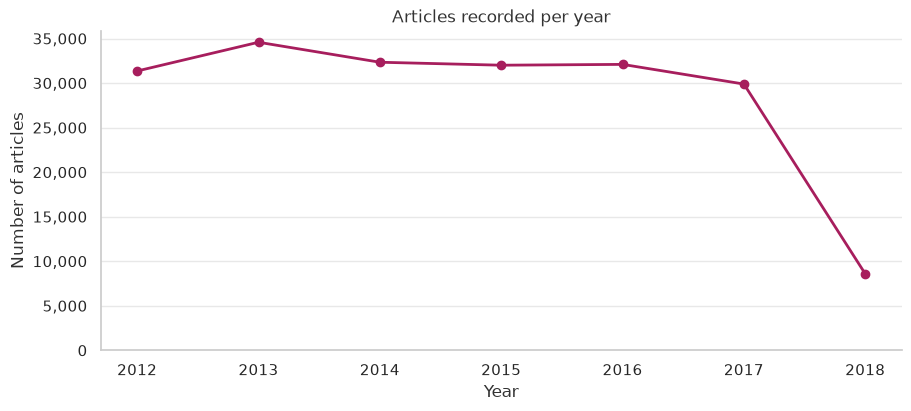

In [18]:
                
#      plot: count articles per year       
# ======================================
# 


annual_counts = (
    df_plot
    .dropna(subset=["year"])
    .groupby("year")
    .size()
    .rename("articles")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")

ax.plot(
    annual_counts["year"].to_numpy(dtype=int),
    annual_counts["articles"],
    color="#A71E5D",
    marker="o",
    linewidth=2
)

ax.set(
    title="Articles recorded per year",
    xlabel="Year",
    ylabel="Number of articles",
    ylim=(0, None)
)
ax.set_xticks(annual_counts["year"].to_numpy(dtype=int))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", visible=False)

plt.show()

### Graded Questions (3 pts each)

Write **a coherent response of approximately 75–125 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits. Straightforward factual questions (such as identifying inputs and outputs) may be answered more briefly when fully addressed.

#### ✅ A. **State the prediction task**  
   - Describe what your model will predict (the *label*).  
   - *Examples:*  
     - “Given a photo of food, predict which of 101 categories it belongs to.”  
     - “Given a news headline + summary, predict its topical category.”  

In [19]:
# Your answer here, NOT in the next cell

a2a = """
For the news dataset, the model will predict the news category. However, 
I will build a new label where the labels are cleaned and de-duplicated. 
"""

In [20]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

a2a = 
For the news dataset, the model will predict the news category. However, 
I will build a new label where the labels are cleaned and de-duplicated. 



#### ✅ B. **Define inputs and outputs**  
   - *Inputs:* what information the model receives (e.g., pixel data, tokenized text).  
   - *Outputs:* the categorical label the model will predict.  

In [21]:
# Your answer here, NOT in the next cell

a2b = """
The input for the model will be tokenized text.
The text will be a combination of the description or the news content, plus
 the headlines, plus
 some data from the authors (i.e., some authors are specialized in some topics and 
 they are unlikely to write some other articles outside their main topics).

The output will be the merged or cleaned news category. 
"""

In [22]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b}")

a2b = 
The input for the model will be tokenized text.
The text will be a combination of the description or the news content, plus
 the headlines, plus
 some data from the authors (i.e., some authors are specialized in some topics and 
 they are unlikely to write some other articles outside their main topics).

The output will be the merged or cleaned news category. 



#### ✅ C. **Identify possible challenges**  
   - Imbalanced classes, noisy data, ambiguous labels, overlapping features, or missing data  
   - *Images:* variation in lighting, color, composition, or size.  
   - *Text:* class imbalance, duplicate stories, short or ambiguous headlines.  

In [23]:
# Your answer here, NOT in the next cell

a2c = """
Some challenges to fix/solve:
- dealing with overlapping news categories, and possibly 2 categories with very similar contents (e.g., green & environment).
- dealing with repetitive weekly news.
- dealing with news categories with less than 1% of the full data. 
- dealing with low count of content texts.
"""

In [24]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c}")

a2c = 
Some challenges to fix/solve:
- dealing with overlapping news categories, and possibly 2 categories with very similar contents (e.g., green & environment).
- dealing with repetitive weekly news.
- dealing with news categories with less than 1% of the full data. 
- dealing with low count of content texts.



#### ✅ D. **Propose how you will prepare or improve the data to address the challenges**  
   - *Images:* resizing, normalization, data augmentation (flips, rotations, brightness, color jitter).  
   - *Text:* tokenization, stop-word removal, TF-IDF, class balancing, embeddings (choose an embedding approach and specify its vector size). 

In [25]:
# Your answer here, NOT in the next cell

a2d = """
To deal with the feature issues
- for most full duplicates (same dates, same text), 
they will be removed (just keeping one copy).
- for the weekly duplicates, date will be added to increase distinction
- for the missing content, they will be kept for now.
- for the missing headlines, they will be kept.
- to add info, if the author has a specialty attached to the name,
their info will be added into the combined text for the input/token.

For target:
- mergings will be done for the overlap or similar categories.
- this will create a new target column.


From there, splitting will be done.

After that, a model like distillBERT will be used.
- using autotokenizer for the distillBERT base.
- since it is a pretrained model, I will not do stop-word removal nor TF-IDF.
- as the pretrained model also has embedding, i will use the provided embedding.
"""

In [26]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2d = {a2d}")

a2d = 
To deal with the feature issues
- for most full duplicates (same dates, same text), 
they will be removed (just keeping one copy).
- for the weekly duplicates, date will be added to increase distinction
- for the missing content, they will be kept for now.
- for the missing headlines, they will be kept.
- to add info, if the author has a specialty attached to the name,
their info will be added into the combined text for the input/token.

For target:
- mergings will be done for the overlap or similar categories.
- this will create a new target column.


From there, splitting will be done.

After that, a model like distillBERT will be used.
- using autotokenizer for the distillBERT base.
- since it is a pretrained model, I will not do stop-word removal nor TF-IDF.
- as the pretrained model also has embedding, i will use the provided embedding.



#### ✅ E. **Specify success metrics**  
   - Identify the metrics you plan to use to evaluate model performance—typically **accuracy** and/or **F1-score**, which are standard for classification tasks.  
   - Briefly explain **why** these metrics are appropriate for your dataset and goal. For instance, accuracy may suffice for well-balanced datasets, while F1-score better reflects performance when some classes are under-represented.
   - If your dataset is **imbalanced**, consider computing **per-class metrics** (e.g., precision, recall, or F1 for each label) or **macro-averaged** scores, which give equal weight to each class regardless of its size—ensuring that minority classes are evaluated fairly.
In some cases, weighted averages (which weight classes by their frequency) or **confusion matrices** can also provide useful insight.
> You haven't run any models yet, and we haven’t studied every possible metric, but you’re encouraged to ask your favorite generative AI tool which evaluation metrics might best fit your dataset!
   - Clearly state how you will interpret success—for example, “Our goal is to achieve at least 80% overall accuracy without large per-class disparities.”

In [27]:
# Your answer here, NOT in the next cell

a2e = """
The news dataset has 41 classes for the target.
Even after reducing some of them due to overlapping or same but just different name corrections,
there are still many categories.

This creates an imbalance data (Politics makes up about 16% of the full data, while Wellness only makes up 9%). 

Thus, I will prioritize macro-F1 metric because it will give each class equal importance regardless of 
the count of articles per category. 
This score would be good for making sure the model has good precision as well as recall.

I also plan to make confusion metrices to compare the results.
"""

In [28]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2e = {a2e}")

a2e = 
The news dataset has 41 classes for the target.
Even after reducing some of them due to overlapping or same but just different name corrections,
there are still many categories.

This creates an imbalance data (Politics makes up about 16% of the full data, while Wellness only makes up 9%). 

Thus, I will prioritize macro-F1 metric because it will give each class equal importance regardless of 
the count of articles per category. 
This score would be good for making sure the model has good precision as well as recall.

I also plan to make confusion metrices to compare the results.



# Problem 3 — Data Preparation and Splits (30 pts)

### Goals

Implement the **data preparation and preprocessing steps** that you proposed in **Problems 1–2**. You’ll clean, normalize, and split your data so that it’s ready for modeling and reproducible modeling.

### Steps to Follow

1. **Load your chosen dataset**

   * Use `datasets.load_dataset()` from **Hugging Face** to load **Food-101** or **HuffPost**.
   * Display basic information (e.g., number of samples, feature names, example entries).

2. **Apply cleaning and normalization**

   * **Text:**

     * Concatenate headline + summary (for HuffPost).
     * Strip whitespace, convert to lowercase if appropriate, and remove empty samples.
     * Optionally remove duplicates or extremely short entries.

3. **Standardize or tokenize the inputs**

   * **Text:**

     * Create a tokenizer or `TextVectorization` layer.
     * Set a target `max_length` based on your analysis from your earlier exploration in this notebook (e.g., 95th percentile).
     * Apply padding/truncation and build tensors for input + labels.

4. **Handle dataset-specific challenges**

   * If you identified **class imbalance**, compute label counts and, if needed, create a dictionary of `class_weights`.
   * If you noted **length or size variance**, verify that your truncation or resizing works as intended.
   * If you planned **noise filtering**, include the cleaning step and briefly explain your criteria (e.g., remove items with missing text or unreadable images).

5. **Create reproducible splits**

   * Split your cleaned dataset into **train**, **validation**, and **test** subsets (e.g., 80 / 10 / 10).
   * Use a fixed random seed for reproducibility (`random_seed = 42`).
   * Use **stratified splits**  (e.g., with `train_test_split` and `stratify = labels`).
   * Display the size of each subset.

6. **Document your pipeline**

   * Summarize your preprocessing steps clearly in Markdown or code comments.
   * Save or display a few representative examples after preprocessing to confirm the transformations are correct.




**Test-set policy:** Create and verify the test split, but **do not train on or evaluate models against it** in this milestone. Fit preprocessing parameters (e.g. vocabulary, scaling) on training data only; apply the fitted transformations to validation and test examples. Apply random augmentation to training data only.


In [29]:
# Your code here; add as many cells as you need but make it clear what the structure is. 


##### DATA HAS BEEN LOADED

                
#      additional function - pulling authors' specialties       
# ======================================
####____◄ many authors have specialties that they most likely write one category only.

possible_markers_for_specialty =    ['contributor', 'author', 'specialist']
extra_words_to_replace =            ['editor', 'author']



def _build_pattern(words: list, whole_word: bool = False) -> str:
    joined = "|".join(re.escape(w) for w in words if w)
    if not joined:
        return ""
    return rf"\b(?:{joined})\b" if whole_word else joined


def pull_author_specialty(
    author,
    marker: list = possible_markers_for_specialty,
    extra_words: list = extra_words_to_replace,
) -> str:
    ## __Return "" for missing or non-text input
    if not isinstance(author, str):
        return ""

    ## __Return "" when no marker pattern exists
    pattern_marker = _build_pattern(marker)
    if not pattern_marker:
        return ""

    ## __Match the first marker, ignoring capitalization
    match = re.search(pattern_marker, author, flags=re.IGNORECASE)
    if match is None:
        return ""

    ## __Extract text after the marker and convert literal \n to a space
    specialty = author[match.end():].replace("\\n", " ")

    ## __Remove unwanted words, if any were provided
    pattern_after = _build_pattern(extra_words, whole_word=True)
    if pattern_after:
        specialty = re.sub(pattern_after, "", specialty, flags=re.IGNORECASE)

    ## __Normalize spaces and trim punctuation
    specialty = " ".join(specialty.split()).strip(",:;- ")

    return specialty



                
#       make function for creating the feature / input text      
# ======================================
# 

def combining_news_text(df)->pd.DataFrame:
    return (
        df 
        .assign(
            cleaned_headline = lambda x: (
                x["headline"] 
                .fillna("")                     ####____◄ make any NA to be empty... not that needed
                .astype("string")               ####____◄ 
                .str.replace(r"\s+", " ", regex = True)     ####____◄ just fixing escape code
                .str.strip()
            ),

            cleaned_content = lambda x: (
                x["short_description"]
                .fillna("") 
                .astype("string")
                .str.replace(r"\s+", " ", regex = True)
                .str.strip()
            ),

            author_spec = lambda x: (
                x['authors']
                .apply(pull_author_specialty)
            )
        )

        .assign(
            combo_text_H_C_     = lambda x: (  
                            x["cleaned_headline"] + "\n" + x["cleaned_content"]
                            ).str.strip()
                ,
            combo_text_H_C_A_   = lambda x: (                       ####____◄ including author's specialty
                            x["cleaned_headline"] + "\n" + x["cleaned_content"] + "\n" + x["author_spec"]
                            ).str.strip()
        )
    )

In [30]:
#### ----------------------------------------------------- ####
                
#      PREPROCESSING       
# ======================================
# 

##_____ CREATE COMBO TEXT _____ ##: using the functions above

df_cleaned_1 = (
    df 
    .pipe(combining_news_text)          ####____◄ create the 2 combo text columns
    .query("combo_text_H_C_ != '' ")    ####____◄ cleaning up rows without any text/input
    .dropna(subset = ['category'])
)


##_____ CLEANUP CONFLICTING/DUPS _____ ##: removing those with same text but diff labels

conflicting_texts = (
    df_cleaned_1
    .groupby("combo_text_H_C_")["category"]
    .nunique()
    .loc[lambda x: x > 1]
    .index
)


df_cleaned_2 = (
    df_cleaned_1
    .loc[lambda x: ~x["combo_text_H_C_"].isin(conflicting_texts)]
    .drop_duplicates(subset=["combo_text_H_C_"], keep="last") ####____◄ for now, selecting that the last repeat is the correct label
    .reset_index(drop=True)
)



##### •••••• ####
##### REVIEWING THE PREPROCESSING 
df_conflicts = (
    df_cleaned_1
    .loc[lambda x: x["combo_text_H_C_"].isin(conflicting_texts)]
    .sort_values(["combo_text_H_C_", "category"])
)

display(df_conflicts[["headline", "combo_text_H_C_", "category", "date"]].iloc[10:30])


print(f"Dataset size after removing empyt text, but not duplicates: {len(df_cleaned_1)}")
print(f"Dataset size after remoivng duplicates: {len(df_cleaned_2)}")

,headline,combo_text_H_C_,category,date
63496,Is Prostitution Just Another Job?,Is Prostitution Just Another Job?\nChelsea Lan...,BUSINESS,2016-03-21
63382,Is Prostitution Just Another Job?,Is Prostitution Just Another Job?\nChelsea Lan...,WOMEN,2016-03-22
199543,"Kelly Rowland's Birthday: Singer Turns 31, Sty...","Kelly Rowland's Birthday: Singer Turns 31, Sty...",BLACK VOICES,2012-02-11
199508,"Kelly Rowland's Birthday: Singer Turns 31, Sty...","Kelly Rowland's Birthday: Singer Turns 31, Sty...",STYLE & BEAUTY,2012-02-11
114431,Marcia,Marcia,COMEDY,2014-08-18
118186,Marcia,Marcia,COMEDY,2014-07-07
114307,Marcia,Marcia,WOMEN,2014-08-19
121328,She's Baaaaack!,She's Baaaaack!,BLACK VOICES,2014-06-01
110816,She's Baaaaack!,She's Baaaaack!,COMEDY,2014-09-28
197992,Stylish Yellow Kitchen Accessories And Appliances,Stylish Yellow Kitchen Accessories And Applian...,FOOD & DRINK,2012-02-28


Dataset size after removing empyt text, but not duplicates: 200848
Dataset size after remoivng duplicates: 200350


In [31]:
            
#      PREPROCESSING       2
# ======================================
# 

##_____ CREATE FINAL LABELS _____ ##: merging some of the overlaps or low counts
label_groups = {
    'ARTS & CULTURE'        :   [ 'ARTS', 'ARTS & CULTURE', 'CULTURE & ARTS'],
    'WORLD NEWS'            :   [ 'WORLDPOST','WORLD NEWS' ,'THE WORLDPOST'   ],
    'PARENTING'             :   [ 'PARENTS', 'PARENTING'   ],
    'STYLE & BEAUTY'        :   [ 'STYLE', 'STYLE & BEAUTY'   ],
    'FOOD & DRINK'          :   [ 'TASTE'  , 'FOOD & DRINK',   ],
    'ENVIRONMENT'           :   [ 'GREEN', 'ENVIRONMENT'   ],
    'WELLNESS'              :   [ 'HEALTHY LIVING' , 'WELLNESS'   ],  
}

## __Convert grouped labels into a lookup dictionary
label_mapping = {
    original: merged
    for merged, originals in label_groups.items()
    for original in originals
}

df_cleaned_3 = (
    df_cleaned_2
    .assign(
        cleaned_news_category = lambda x: (
            x["category"]
            .map(label_mapping)
            .fillna(x["category"])
        )
    )
)


##### •••••• ####
##### REVIEWING THE PREPROCESSING 

view_content(df_cleaned_3.sample(3)[["category", "cleaned_news_category", "combo_text_H_C_A_"]])

,category,cleaned_news_category,combo_text_H_C_A_
67939,POLITICS,POLITICS,"Arizona Wants To Secede From The U.S. Court That Has Long Been Its Home\nJohn McCain says that anyone who has followed the 9th Circuit's rulings ""wants to get the hell out."""
114812,SPORTS,SPORTS,"The Live Wire: Tsonga's Triumph\nOutside of Nadal, every member of the Big 4 rolled into Toronto for the Rogers Cup at the start of this week, and every single one fell to Tsonga.\nGrowth Strategist"
32848,WEIRD NEWS,WEIRD NEWS,Rejected! Youth Basketball Coach Appears To Block Own Player's Shot In A Game\nSports mentoring may have just hit a new low.


<div style="
    background: #140e36;
    color: white;
    padding: 22px 26px;
    border-radius: 8px;
    margin: 32px 0 20px 0;
    width: 80%
">
    <div style="color: #84ff00; font-size: .8em;">
        SECTION 03
    </div>
    <h4 style="color: white; margin: 8px 0; weight: 700"> SPLIT ----     </h4>
    <p style="color: #d6d0e4; margin: 0;">
    </p>
</div>

In [32]:
#### ----------------------------------------------------- ####

                
#      SPLITTING       
# ======================================
# 


SAMPLE_FRAC = 1         # 0.25 

SEED = 42
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)


TEXT_INPUT_COL = "combo_text_H_C_"
NEWS_CATEGORY = "cleaned_news_category"

df_model = df_cleaned_3.copy()



##_____ splitting to 80-20 first _____ ##: 
df_train_full, df_holdout = (
    train_test_split(
        df_model,
        test_size       = 0.20 , 
        stratify        = df_model[NEWS_CATEGORY],
        random_state    = SEED
    )
)

##_____ splitting again, the holdout, for validation _____ ##: 
df_val, df_test = (
    train_test_split(
        df_holdout,
        test_size       = 0.50 ,            ####____◄ so.. 20% into 10% and 10%
        stratify        = df_holdout[NEWS_CATEGORY],
        random_state    = SEED
    )
)


##_____ Sampled training data only _____ ##

if SAMPLE_FRAC == 1.0:
    df_train = df_train_full.copy()
else:
    df_train, _ = train_test_split(
        df_train_full,
        train_size=SAMPLE_FRAC,
        stratify=df_train_full[NEWS_CATEGORY],
        random_state=SEED
    )



##_____ label & prep sets _____ ##: 

label_encoder = LabelEncoder()  ####____◄ category-to-integer mapping


label_encoder.fit(df_train_full[NEWS_CATEGORY])

y_train         = label_encoder.transform(df_train[NEWS_CATEGORY])
y_val           = label_encoder.transform(df_val[NEWS_CATEGORY])

# x_train         = df_train[TEXT_INPUT_COL].to_numpy(dtype=str)
# x_val           = df_val[TEXT_INPUT_COL].to_numpy(dtype=str)

x_train = tf.constant(
    df_train[TEXT_INPUT_COL].fillna("").astype(str).tolist(),
    dtype=tf.string
)

x_val = tf.constant(
    df_val[TEXT_INPUT_COL].fillna("").astype(str).tolist(),
    dtype=tf.string
)


NUM_NEWS_CATEGORY = len(label_encoder.classes_)


I0000 00:00:1794688588.621621   29964 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6071 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2070 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


In [33]:
##### •••••• ####
##### REVIEWING THE SPLIT
# 


split_sizes = pd.Series({
    "train": len(df_train),
    "validation": len(df_val),
    "test": len(df_test)
}).to_frame("articles_count")



split_category_pct = (
    pd.concat(
        {
            "train": df_train[NEWS_CATEGORY].value_counts(normalize=True),
            "validation": df_val[NEWS_CATEGORY].value_counts(normalize=True),
            "test": df_test[NEWS_CATEGORY].value_counts(normalize=True)
        },
        axis=1
    )
    .fillna(0)
    .mul(100)
    .round(2)
)
print("Split of articles between sets:")
display(split_sizes.T)

print("Split of each label")
display(split_category_pct)

Split of articles between sets:


,train,validation,test
articles_count,160280,20035,20035


Split of each label


,train,validation,test
cleaned_news_category,,,
POLITICS,16.33,16.33,16.33
WELLNESS,12.23,12.23,12.23
ENTERTAINMENT,8.01,8.02,8.01
PARENTING,6.26,6.26,6.26
STYLE & BEAUTY,5.87,5.87,5.86
TRAVEL,4.93,4.93,4.94
WORLD NEWS,4.20,4.20,4.20
FOOD & DRINK,4.15,4.15,4.15
QUEER VOICES,3.15,3.15,3.15


In [34]:
##### •••••• ####
##### REVIEWING THE BEST LENGTH

df_sample = (
    df_train
    .sample(n=min(5_000, len(df_train)), random_state=42)
    .reset_index(drop=True)
)

text_inputs = {
    "headline": df_sample["headline"].fillna("").astype(str),
    "headline_description": df_sample["combo_text_H_C_"],
    "headline_desc_author": df_sample["combo_text_H_C_A_"]
}

test_tokenizer = keras_hub.models.DistilBertTokenizer.from_preset(
    "distil_bert_base_en_uncased"
)

def get_token_lengths(text):
    tokens = test_tokenizer(text.to_numpy())

    if hasattr(tokens, "row_lengths"):
        return tokens.row_lengths().numpy()

    return [len(sequence) for sequence in tokens]



df_lengths = pd.DataFrame({
    name: get_token_lengths(text)
    for name, text in text_inputs.items()
}).add(2)

## _Token-length distribution
length_summary = (
    df_lengths
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95])
    .round(1)
)

## _Percentage of articles that would lose at least one token
truncation_pct = pd.DataFrame({
    limit: df_lengths.gt(limit).mean().mul(100)
    for limit in [64, 128, 256, 300, 512]
}).rename_axis(columns="sequence_length").round(2)

display(length_summary)
display(truncation_pct)

,headline,headline_description,headline_desc_author
count,5000.0,5000.0,5000.0
mean,14.7,39.9,43.1
std,4.6,17.2,20.1
min,4.0,4.0,5.0
50%,15.0,38.0,40.0
75%,18.0,49.0,53.0
90%,21.0,62.1,71.0
95%,22.0,70.1,81.0
max,39.0,219.0,219.0


sequence_length,64,128,256,300,512
headline,0.00,0.00,0.0,0.0,0.0
headline_description,8.54,0.14,0.0,0.0,0.0
headline_desc_author,15.42,0.14,0.0,0.0,0.0


### Grading for Problem 3 (30 pts)

- **Implementation (18 pts):** correct data loading and cleaning; appropriate preprocessing; reproducible, separate train/validation/test splits with leakage prevention; and checks/outputs demonstrating that the prepared data are suitable for modeling.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual implementation and cite your notebook results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

#### ✅ A. **Data Loading and Cleaning:**
   Describe how you loaded your dataset and the key cleaning steps you implemented (e.g., handling missing data, normalizing formats, or removing duplicates).



In [35]:
# # Your answer here, NOT in the next cell

# a3a = """
# The Huffpost dataset was loaded from the dataset package: load_dataset().

# This immutable file was transformed into Pandas dataframe to make it easier to work with.

# Cleaning steps:
# - Dealing with missing data:
#     - While there are 18% of data missing authors' information, 
#     this is not detrimental and I left it alone.

#     - There are 9.8% of missing short description/content. 
#     But the majority still have headlines and I kept these as headlines could give enough info.

#     - There are only 6 (0.003%) missing headline.
#     Among those, 5 articles are missing both headlines and descriptions, and I remove these.

# - Dealing with duplicates:
#     - There almost 500 articles that have the same headlines and descriptions. 
#     A majority of these articles  have issues where they have different labels. 
#     Some of the labels are difficult to determine due to overlapping topics.
#     While not necessary correct for all, there are several articles that seem duplicated
#      because the previous submission (or date of submission) show wrong label and the new
#      or later version is the correct label. 
#     Therefore, I selected the last of the duplicates to be kept. 

#     - This edit also causes the duplicates because they are weekly posts (e.g., weekly top tweets), 
#     got removed and selected the last entry only. 
#     I have not explored if there is any other feature engineering that could help distinguish 
#     weekly articles like this.
# """

In [36]:
a3a = """
The Huffpost dataset was loaded from the dataset package: load_dataset().

This immutable file was transformed into Pandas dataframe.

Cleaning steps:
- Dealing with missing data:
    - While there are 18% of data missing authors, this is not detrimental and I left it alone.

    - There are 9.8% of missing short description. 
    But the majority still have headlines and I kept these as headlines could give enough info.

    - There are only 6 (0.003%) missing headline.
    Among those, 5 articles are missing both headlines and descriptions, and I remove these.

- Dealing with duplicates:
    - There almost 500 articles that have the same headlines and descriptions. 
    A majority of these articles  have issues where they have different labels. 
    While not necessary correct for all, there are several articles that seem duplicated
     because the previous submission (or date of submission) show wrong label and the new
     or later version is the correct label. 
    Therefore, I selected the last of the duplicates to be kept. 

    - This edit also causes the duplicates because they are weekly posts (e.g., weekly top tweets), 
    got removed and selected the last entry only.
"""

In [37]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a}")

a3a = 
The Huffpost dataset was loaded from the dataset package: load_dataset().

This immutable file was transformed into Pandas dataframe.

Cleaning steps:
- Dealing with missing data:
    - While there are 18% of data missing authors, this is not detrimental and I left it alone.

    - There are 9.8% of missing short description. 
    But the majority still have headlines and I kept these as headlines could give enough info.

    - There are only 6 (0.003%) missing headline.
    Among those, 5 articles are missing both headlines and descriptions, and I remove these.

- Dealing with duplicates:
    - There almost 500 articles that have the same headlines and descriptions. 
    A majority of these articles  have issues where they have different labels. 
    While not necessary correct for all, there are several articles that seem duplicated
     because the previous submission (or date of submission) show wrong label and the new
     or later version is the correct label. 
    Therefo

#### ✅ B. **Preprocessing and Standardization:**
   Summarize your preprocessing pipeline. Include any normalization, tokenization, resizing, or augmentation steps, and explain why each was necessary for your dataset.
  

In [38]:
# Your answer here, NOT in the next cell

a3b = """
Several phases done in preprocessing:
1. Feature engineering:
    - Mostly combining the text.
    - Some authors put their specialties information or books.
    This could be a feature as well. Thus, 
    I wrote a function to pull information if the author
    has some info like this.

    - The resulting text that would be used for the input is 
    a combination of headline, description, and author's information if available. 

2. Cleaning the duplicates as mentioned before.

3. Merging labels that are similars
    - Some labels such as World News and The WorldPost are the same category, 
    except that one is a rename of the other. 

4. Tokenization is done after the split using distil BERT.
    - The result of a sampled data, shows that if headline only, 64 max lenght is enough.
    - But for the headline + description, using 64 as max lenght, caused 8% to be dropped in the training.
    - Seems that 128 is the safe lenght. 
"""

In [39]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b}")

a3b = 
Several phases done in preprocessing:
1. Feature engineering:
    - Mostly combining the text.
    - Some authors put their specialties information or books.
    This could be a feature as well. Thus, 
    I wrote a function to pull information if the author
    has some info like this.

    - The resulting text that would be used for the input is 
    a combination of headline, description, and author's information if available. 

2. Cleaning the duplicates as mentioned before.

3. Merging labels that are similars
    - Some labels such as World News and The WorldPost are the same category, 
    except that one is a rename of the other. 

4. Tokenization is done after the split using distil BERT.
    - The result of a sampled data, shows that if headline only, 64 max lenght is enough.
    - But for the headline + description, using 64 as max lenght, caused 8% to be dropped in the training.
    - Seems that 128 is the safe lenght. 



#### ✅ C. **Train/Validation/Test Splits:**
   Explain how you divided your data into subsets, including the split ratios, random seed, and any stratification or leakage checks you used to verify correctness.


In [40]:
# Your answer here, NOT in the next cell

a3c = """
Splitting:
    - First, I split the data into train & holdout set.
        - The split is 80% training, and 20% holdout;
        - Stratified by the label that is the news category from the merged labels;
        - and using random seed 42.

    - Next, the holdout set was split again into validation and test set.
        - The split is 50% each, creating both sets are 10% of the whole dataset equally. 
        - The rest of the configurations are the same.

    - Next, the news category was encoded.
        - To prevent leakage, only the training set (y_train) is applied with .fit_transform().
        - The validation and test sets only get applied with .transform()
    
    - From here, I finalized the x and y for the training, validation, and test sets.
"""

In [41]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3c = {a3c}")

a3c = 
Splitting:
    - First, I split the data into train & holdout set.
        - The split is 80% training, and 20% holdout;
        - Stratified by the label that is the news category from the merged labels;
        - and using random seed 42.

    - Next, the holdout set was split again into validation and test set.
        - The split is 50% each, creating both sets are 10% of the whole dataset equally. 
        - The rest of the configurations are the same.

    - Next, the news category was encoded.
        - To prevent leakage, only the training set (y_train) is applied with .fit_transform().
        - The validation and test sets only get applied with .transform()

    - From here, I finalized the x and y for the training, validation, and test sets.



#### ✅ D. **Class Distribution and Balance:**
   Report your label counts and describe any class imbalances you observed. If applicable, explain how you addressed them (e.g., weighting, oversampling, or data augmentation).


In [42]:
# Your answer here, NOT in the next cell

a3d = """
The class imbalance is high, as seen in the `split_category_pct` output. 
After merging and fixing some of the labels, the total category is down from 41 to 32.

The most frequent category is Politics with 16% of the whole data.
Wellness was low but due to merging with Healthy Living, the total becomes 12%. 
But there are still 18 other categories that are lower than 2%. 

Class weighting will be tested after testing the base model later.
Some ideas is to use sklearn compute_class_weight, but this has some implications on 
accuracy in some classes too. So, I will check the macro F1 during the exploration of the best models later.
"""

In [43]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3d = {a3d}")

a3d = 
The class imbalance is high, as seen in the `split_category_pct` output. 
After merging and fixing some of the labels, the total category is down from 41 to 32.

The most frequent category is Politics with 16% of the whole data.
Wellness was low but due to merging with Healthy Living, the total becomes 12%. 
But there are still 18 other categories that are lower than 2%. 

Class weighting will be tested after testing the base model later.
Some ideas is to use sklearn compute_class_weight, but this has some implications on 
accuracy in some classes too. So, I will check the macro F1 during the exploration of the best models later.



# Problem 4 — Baseline Model (30 pts)


## Goal

Build and train a **simple, fully functional baseline model** to establish a reference level of performance for your dataset.
This baseline will help you evaluate whether later architectures and fine-tuning steps actually improve results.


### Steps to Follow

1. **Construct a baseline model**

   * **Text:**
     Use a small embedding-based classifier such as
     `Embedding → GlobalAveragePooling → Dense → Softmax`.
   * Keep the model small enough to train in minutes on Colab.

2. **Compile the model**

   * Optimizer: `Adam` or `AdamW`.
   * Loss: Use `categorical_crossentropy` for one-hot-encoded labels or `sparse_categorical_crossentropy` for integer class labels.
   * Metrics: at least `accuracy`; add `F1` if appropriate.

3. **Train and validate**

   * Use **early stopping** on validation loss with a patience of approximately 5 epochs.
   * Record number of epochs trained and total runtime.

4. **Visualize results**

   * Plot **training vs. validation accuracy and loss**.
   * Carefully observe: does the model underfit, overfit, or generalize reasonably?

5. **Report baseline performance**

   * The most important metric is the **validation accuracy at the epoch of minimum validation loss**; this serves as your **benchmark** for all later experiments in the final project.
   * **Do not evaluate on the test set yet.** Report validation performance only. Preserve the test split for final evaluation.

In [44]:
# Your code here; add as many cells as you need but make it clear what the structure is. 

#      baseline       
# ======================================
# 

MAX_LEN         = 128
VOCAB_SIZE      = 20_000
EMBED_DIM       = 64

BATCH           = 32
EPOCHS          = 15
LR              = 1e-3


##_____ Tokenization _____ ##

vectorizer = keras.layers.TextVectorization(
    max_tokens              = VOCAB_SIZE,
    output_mode             = "int",
    output_sequence_length  = MAX_LEN
)

# Learn vocabulary from training data only
vectorizer.adapt(x_train)


##_____ Construct model _____ ##

model = (
        keras
        .Sequential([
                    keras.Input(shape=(), dtype="string"),

                    vectorizer,

                    keras.layers.Embedding(
                                input_dim       = len(vectorizer.get_vocabulary()),
                                output_dim      = EMBED_DIM,
                                mask_zero       = True
                    ),

                    keras.layers.GlobalAveragePooling1D(),

                    keras.layers.Dense(64, activation="relu"),

                    keras.layers.Dense(
                        NUM_NEWS_CATEGORY,
                        activation      ="softmax",
                        dtype           ="float32"
                    )
                ]
                )
)



##_____ Compile _____ ##

model.compile(
    optimizer       = keras.optimizers.Adam(learning_rate=LR),
    loss            = keras.losses.SparseCategoricalCrossentropy(),
    metrics         =[keras.metrics.SparseCategoricalAccuracy(name="acc")]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 128)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 128, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,286,240 (4.91 MB)

 Trainable params: 1,286,240 (4.91 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:

#      TRAINING
# ======================================

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start = time.perf_counter()

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH,
    callbacks=[early_stop],
    verbose=1
)

elapsed = time.perf_counter() - start


##_____ Training history _____ ##

hist_df = (
    pd.DataFrame(history.history)
    .assign(
        epoch=lambda x: np.arange(1, len(x) + 1)
    )
)

best = hist_df["val_loss"].idxmin()


##_____ Validation prediction _____ ##

val_pred = model.predict(
    x_val,
    batch_size=64,
    verbose=0
).argmax(axis=-1)


##_____ Results table _____ ##

results_df = pd.DataFrame([{
    "model": "Embedding baseline",
    "train_fraction": SAMPLE_FRAC,
    "best_epoch": int(hist_df.loc[best, "epoch"]),
    "epochs_trained": len(hist_df),
    "val_loss": hist_df.loc[best, "val_loss"],
    "val_acc": hist_df.loc[best, "val_acc"],
    "val_macro_f1": f1_score(
        y_val,
        val_pred,
        average="macro"
    ),
    "runtime_seconds": round(elapsed, 1)
}])

display(results_df)


Epoch 1/15
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 61s 11ms/step - acc: 0.5329 - loss: 1.7794 - val_acc: 0.6251 - val_loss: 1.3919
Epoch 2/15
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 57s 11ms/step - acc: 0.6847 - loss: 1.1604 - val_acc: 0.6476 - val_loss: 1.3047
Epoch 3/15
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 58s 11ms/step - acc: 0.7321 - loss: 0.9606 - val_acc: 0.6483 - val_loss: 1.3177
Epoch 4/15
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 58s 11ms/step - acc: 0.7666 - loss: 0.8226 - val_acc: 0.6462 - val_loss: 1.3731
Epoch 5/15
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 58s 12ms/step - acc: 0.7969 - loss: 0.7116 - val_acc: 0.6408 - val_loss: 1.4622
Epoch 6/15
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 57s 11ms/step - acc: 0.8239 - loss: 0.6170 - val_acc: 0.6342 - val_loss: 1.5800
Epoch 7/15
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 57s 11ms/step - acc: 0.8493 - loss: 0.5335 - val_acc: 0.6288 - val_loss: 1.7235


,model,train_fraction,best_epoch,epochs_trained,val_loss,val_acc,val_macro_f1,runtime_seconds
0,Embedding baseline,1,2,7,1.304717,0.647567,0.499584,406.4


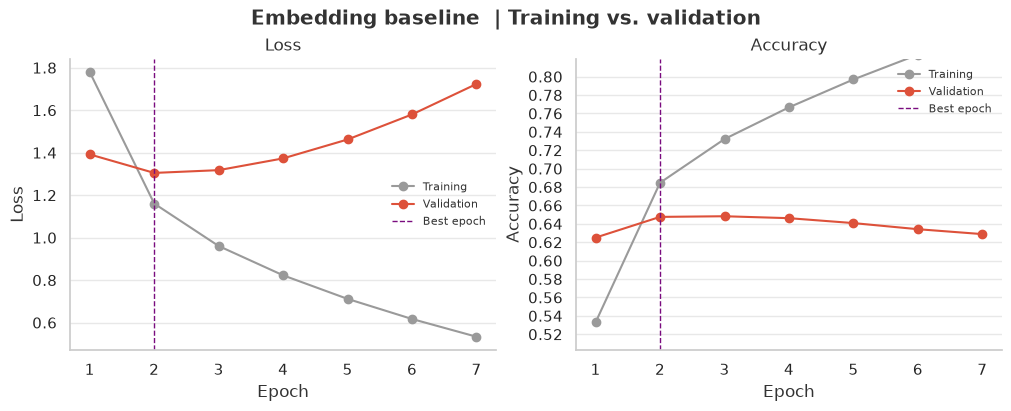

In [46]:

#      TRAINING CURVES
# ======================================

def plot_curves(hist_df, sup_title):

    best = hist_df["val_loss"].idxmin()
    best_epoch = hist_df.loc[best, "epoch"]

    measures = [
        ("loss", "val_loss", "Loss"),
        ("acc", "val_acc", "Accuracy")
    ]

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(10, 4),
        layout="constrained"
    )

    for ax, (train_col, val_col, title) in zip(axes, measures):

        ax.plot(
            hist_df["epoch"],
            hist_df[train_col],
            color="#9a9a9a",
            marker="o",
            label="Training"
        )

        ax.plot(
            hist_df["epoch"],
            hist_df[val_col],
            color="#dd513a",
            marker="o",
            label="Validation"
        )

        ax.axvline(
            best_epoch,
            color="#7a0c7f",
            linestyle="--",
            linewidth=1,
            label="Best epoch"
        )

        ax.set(
            title=title,
            xlabel="Epoch",
            ylabel=title
        )


        if title == 'Accuracy':
            values = hist_df[[train_col , val_col]].to_numpy()
            y_min = max(0, values.min() -0.03)
            y_max = min(1, values.max() - 0.03)
            ax.set_ylim(y_min, y_max)
            ax.yaxis.set_major_locator(plt.MaxNLocator(nbins= 20))

        ax.grid(axis="y", color="#e8e8e8")
        ax.grid(axis="x", visible=False)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.legend(frameon=False, fontsize=8)

    fig.suptitle(
        (f"{sup_title}  | Training vs. validation") ,
        fontweight="bold"
    )

    plt.show()


plot_curves(hist_df, "Embedding baseline")


### Grading for Problem 4 (30 pts)

- **Implementation (18 pts):** a functional, appropriate baseline model; correct compilation and training; appropriate use of training and validation sets (no test evaluation); learning curves; and reproducible, clearly reported validation results.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual model, training behavior, and results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.



#### A. **Model Architecture:**
   Describe your baseline model and justify why this structure suits your dataset.

In [47]:
# Your answer here, NOT in the next cell

a4a = """
I tested the baseline model using keras sequential with embedding, global average pool, one dense layer before output/softmax layer.

Before that, I include tokenization using TextVectorizer.

The max lenght of the token was decided to be 128, based on analysis above that 128 length could capture
 about 98-99% of the data.

The neural network also uses:
- Adam as optimizer with base learning rate of 1e-3.
- SparseCategoricalCrossentropy for the loss as the label has been encoded. 

This is just the baseline model to compare with the large text tokenization that can be compared 
with Distil BERT later. 
"""

In [48]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 
I tested the baseline model using keras sequential with embedding, global average pool, one dense layer before output/softmax layer.

Before that, I include tokenization using TextVectorizer.

The max lenght of the token was decided to be 128, based on analysis above that 128 length could capture
 about 98-99% of the data.

The neural network also uses:
- Adam as optimizer with base learning rate of 1e-3.
- SparseCategoricalCrossentropy for the loss as the label has been encoded. 

This is just the baseline model to compare with the large text tokenization that can be compared 
with Distil BERT later. 



#### B. **Training Behavior:**
   Summarize the model’s training and validation curves. What trends did you observe?

In [49]:
# Your answer here, NOT in the next cell

a4b = """
The training stopped at epoch 7 as the model did not perform better after epoch 2.
I tested using 25% training data as well as full 100% training data.
In both instances, the loss curve and the accuracy curve kept being improved, but the validation curves 
stopped showing improvement.

While the loss of validation has greater trend in getting worse, the accuracy curve is slower but still show 
some issues of overfitting after epoch 2.
"""

In [50]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b}")

a4b = 
The training stopped at epoch 7 as the model did not perform better after epoch 2.
I tested using 25% training data as well as full 100% training data.
In both instances, the loss curve and the accuracy curve kept being improved, but the validation curves 
stopped showing improvement.

While the loss of validation has greater trend in getting worse, the accuracy curve is slower but still show 
some issues of overfitting after epoch 2.



####  C. **Baseline Metrics:**
   Report validation metrics only. What does this performance tell you about dataset difficulty?

In [51]:
# Your answer here, NOT in the next cell

a4c = """
The validation loss at epoch 2 shows as 1.3, however the validation accuracy is only 0.648 and the 
macro F1 only 0.499. 

With this baseline model, it seems that the model has not been performing well with the validation set.

"""

In [52]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4c = {a4c}")

a4c = 
The validation loss at epoch 2 shows as 1.3, however the validation accuracy is only 0.648 and the 
macro F1 only 0.499. 

With this baseline model, it seems that the model has not been performing well with the validation set.




####   D. **Reflection:**
   What are the main limitations of your baseline? Which specific improvements (depth, regularization, pretraining) would you try next?
  

In [53]:
# Your answer here, NOT in the next cell

a4d = """
At the moment, the baseline model uses preset text tokenization. 
This method could be improved due to the issue of imbalance classes where approximatly half of the classes 
are lower than 5% of the data. 

Another possible fix is to try using Distil BERT pretrained model to make better tokenization preprocessing.

"""

In [54]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4d = {a4d}")

a4d = 
At the moment, the baseline model uses preset text tokenization. 
This method could be improved due to the issue of imbalance classes where approximatly half of the classes 
are lower than 5% of the data. 

Another possible fix is to try using Distil BERT pretrained model to make better tokenization preprocessing.




# Final checks and AI-use disclosure (read but not graded)

**AI question:** Describe what use you made of generative AI tools in preparing this milestone, consistent with CDS policy. Include what you used the tools for and how you verified the results.



**Your answer here:**

To find out more about the dataset, such as its data dictionary
https://www.perplexity.ai/search/5fbfb8e1-24a2-437a-a47f-40eee50d283d


Find out more info on codes and syntax
https://www.perplexity.ai/session/0b26b3f2-2ee3-42d6-807c-3ac452695c0f
https://www.perplexity.ai/session/403a351a-255a-4d5e-8d2a-4b3c3f3df90f


Ask AI to help with errors
https://www.perplexity.ai/session/dd5aafb6-eafb-4cbe-b75c-4ccf3b1f4b11


Finding ways or other techniques for feature engineer text
https://www.perplexity.ai/session/041cd962-4c31-4ef9-806e-8e4995a45dd2



### Submission checklist

- [x] I explored both datasets, chose one, and removed the unused dataset’s starter section.
- [x] The submitted notebook has my name and answers to Problems 1–4.
- [x] The notebook contains the code, relevant outputs, plots, and training/validation metrics for the baseline.
- [x] The test set was created but **not used to make modeling decisions or report baseline test performance**.
- [x] I restarted the kernel and ran the notebook from top to bottom, without errors.
- [x] I documented random seeds, dataset sampling, dependencies, and AI-tool use.


# Appendix: A quick guide to Hugging Face Datasets

#### 1) What are they?

* A **table-like** dataset: rows = examples, columns = named fields (e.g., `"image"`, `"label"`, `"headline"`).
* Backed by **Apache Arrow** → fast, memory-efficient, lazy transforms.
* Two core objects:

  * `Dataset` — one table of rows/columns.
  * `DatasetDict` — a dict of splits, e.g. `{"train": Dataset, "val": Dataset, "test": Dataset}`.


#### 2) Load and inspect

```python
from datasets import load_dataset

# Food-101 (images)
food = load_dataset("food101", split="train+validation")  # both splits at once
len(food), food.column_names, food.features
# -> (≈101000, ['image','label'], {'label': ClassLabel(num_classes=101, names=[...])})

# Access by name (not by numeric column index!)
row0 = food[0]
img0, y0 = row0["image"], row0["label"]     # PIL image, int id
label_names = food.features["label"].names
label_names[y0]
```

For text (HuffPost JSON mirror):

```python
url = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff = load_dataset("json", data_files=url, split="train")
huff.column_names  # e.g. ['headline','short_description','category','authors','link','date']
```


#### 3) Common transforms

`Dataset`s are **immutable**: ops return a new dataset.

* **Map** (add/modify columns):

```python
def mk_text(ex):
    h = (ex.get("headline") or "").strip()
    s = (ex.get("short_description") or "").strip()
    return {"text": (h + " [SEP] " + s).strip()}

huff = huff.map(mk_text)  # adds 'text' column
```

* **Class-encode** labels (strings → integers with a vocabulary):

```python
from datasets.features import ClassLabel
if not isinstance(huff.features["category"], ClassLabel):
    huff = huff.class_encode_column("category")  # now ints with .names
```

* **Filter / select / rename / drop**:

```python
small = huff.select(range(5000))  # first 5k rows
huff = huff.remove_columns(["authors","link","date"])
huff = huff.rename_column("category", "label")
```


#### 4) Splitting & shuffling

```python
# Stratified 80/10/10 on Food-101 by 'label'
from datasets import DatasetDict
label_col = "label"

tmp = food.train_test_split(test_size=0.10, seed=42, stratify_by_column=label_col)
train_val = tmp["train"].train_test_split(test_size=1/9, seed=42, stratify_by_column=label_col)
ds = DatasetDict(train=train_val["train"], val=train_val["test"], test=tmp["test"])

len(ds["train"]), len(ds["val"]), len(ds["test"])
```

* `train_test_split` is **random by default** (reproducible with `seed=`).
* You typically **don’t need to pre-shuffle** datasets if your training dataloader already shuffles each epoch.


#### 5) Working with images

Use `with_transform` to apply on-the-fly resizing/augmentation and return tensors:

```python
import torchvision.transforms as T
from torch.utils.data import DataLoader
import torch, math, random

IM_SIZE = 224
train_tfms = T.Compose([T.RandomResizedCrop(IM_SIZE), T.RandomHorizontalFlip(), T.ToTensor()])
eval_tfms  = T.Compose([T.Resize(256), T.CenterCrop(IM_SIZE), T.ToTensor()])

def add_pixel_values(ex, tfms):  # ex['image'] -> ex['pixel_values']
    ex = dict(ex); ex["pixel_values"] = tfms(ex["image"]); return ex

train_t = ds["train"].with_transform(lambda ex: add_pixel_values(ex, train_tfms))
val_t   = ds["val"].with_transform(lambda ex: add_pixel_values(ex, eval_tfms))

def collate(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "labels": torch.tensor([b["label"] for b in batch])}

train_loader = DataLoader(train_t, batch_size=64, shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(val_t,   batch_size=64, shuffle=False, collate_fn=collate)
```

### 6) Working with Text

You can preprocess and tokenize text datasets using either a **transformer tokenizer** or a **linguistic pipeline like spaCy**, depending on your model type and goals.


#### Option A: Transformer Tokenizer (for fine-tuning models like BERT or DistilBERT)

Use a pretrained tokenizer with the Hugging Face `map` method to efficiently process your dataset in batches:

```python
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize(batch):
    return tok(batch["text"], truncation=True, padding="max_length", max_length=128)

tokenized = huff.map(
    tokenize,
    batched=True,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

This produces token IDs, attention masks, and other fields expected by transformer models.
Use this approach if your project involves fine-tuning pretrained language models.


#### Option B: spaCy Tokenization and Cleaning (for classical ML or custom preprocessing)

If you are **not using transformers**, or if you want to explore feature engineering (e.g., TF-IDF, word frequency, or embedding averages), you can preprocess text with **spaCy** instead.

```python
# !pip install spacy
# !python -m spacy download en_core_web_sm

import spacy
from datasets import load_dataset

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser", "textcat"])
STOP = spacy.lang.en.stop_words.STOP_WORDS

def spacy_clean(batch):
    docs = list(nlp.pipe(batch["text"], batch_size=1000))
    cleaned = []
    for doc in docs:
        tokens = [t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]
        cleaned.append(" ".join(tokens))
    return {"text_clean": cleaned, "len_tokens": [len(c.split()) for c in cleaned]}

huff = huff.map(
    spacy_clean,
    batched=True,
    batch_size=1000,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

The resulting column `text_clean` can be used with:

* `TfidfVectorizer` (Scikit-learn)
* `TextVectorization` (Keras)
* or any other custom embedding method.

> 💡 **Tip:** spaCy is ideal for lightweight NLP pipelines or for models that rely on explicit preprocessing (lemmatization, stopword removal). Transformer tokenizers, by contrast, expect *raw text* and handle subword tokenization internally.



#### 7) Slicing, concatenating, saving

```python
# Slicing
head_1000 = food.select(range(1000))
tail_10pct = food.select(range(int(0.9*len(food)), len(food)))

# Concatenate splits/datasets
from datasets import concatenate_datasets
all_train = concatenate_datasets([ds["train"], ds["val"]])

# Save / reload
ds.save_to_disk("food101_splits")
from datasets import load_from_disk
ds2 = load_from_disk("food101_splits")
```


#### 8) Quick “gotchas”

* **Columns by name** (strings), not numeric indices.
* Avoid converting huge columns to `list(...)` unless necessary; prefer vectorized ops with `map`, `filter`, `select`.
* `PYTHONHASHSEED` must be set **before** the Python process starts to matter; use explicit `seed=` arguments for reproducibility.
* Datasets print **previews** (e.g., `Column([6, 6, 6, ...])` is just the first few values).


#### 9) A minimal checklist to follow

1. `load_dataset(...)` → confirm `column_names`, `features`.
2. Build any needed columns (`"text"`), and **class-encode** labels if strings.
3. Make a **stratified 80/10/10** split (`train_test_split` ×2).
4. Do **EDA**: class counts, sample printouts or image grids.
5. For training:

   * **images** → `with_transform` + DataLoader
   * **text** → tokenizer via `.map(...)` + trainer/model pipeline
6. Save your `DatasetDict` with `save_to_disk(...)` (optional for text but handy, **don't** use it for big image datasets).

